# 06 · Order book snapshots: Binance spot vs USDⓈ-M, one 45-minute window

Module **M1: the order book** (Phase 1).

**Task.** Take a snapshot of four order books every 10 seconds for 45 minutes, store **every
price level** (raw), and measure the spread and the depth near the mid. The stored snapshots are
the **input of notebook 07**, which will simulate market orders of 1k / 10k / 100k / 1M USDT
walking these books.

**Markets** (public data, no API key, via ccxt):
- Binance spot **BTC/USDT**, **ETH/USDT** and one less liquid altcoin (chosen by a rule in
  section 3);
- Binance USDⓈ-M perpetual **BTC/USDT:USDT** (ccxt id `binanceusdm`).

**What an order book is.** Resting limit orders, grouped by price. **Bids** are offers to buy,
**asks** are offers to sell. The best bid is the highest buy price, the best ask the lowest sell
price; the gap between them is the **spread**, and the **mid** is the point halfway. A market
order is filled against these levels, best first: a small order pays about half the spread
versus the mid; a large one also "walks" deeper levels at worse prices (that is notebook 07).
**Depth within ±x%** is how much is resting between the mid and x% away: it says how large an
order can be before the price moves x%.

**Hypothesis (lab rule 1).** *I believe the BTC perpetual has a smaller spread (in bps) and more
depth near the mid than BTC spot on the same exchange, because most BTC trading on Binance
happens on the perpetual (leverage, no need to hold coins), which attracts more market makers
quoting tight prices. I believe the altcoin has a spread several times wider and far less
depth, because fewer market makers compete there.*
*(Honest note: written after the step-0 probe of the API, which already showed the perpetual's
book being denser near the mid, so the spot-vs-perp check is not blind.)*

**Scope.** This is **one window of 45 minutes at one hour of one weekday**. Spread and depth
change with the hour, the day and the market regime, so nothing here is a general statement
about these markets.

## 1. Setup and parameters

**Fixed before the collection** (lab rule 4). Changes after inspection are labeled
**post-inspection**.

- Interval **10 s**, duration **45 min** (270 rounds); one round = one snapshot of each of the
  4 markets, taken one after the other.
- Levels per side: **5000** on spot (documented maximum of `/api/v3/depth`), **1000** on USDⓈ-M
  (maximum of `/fapi/v1/depth`). Asking for the maximum is the only way to cover ±1% and a
  1M USDT order; section 2 checks whether it is enough.
- Bands around the mid: **±0.1%** and **±1%**. *Post-inspection:* **±0.2%** added, the narrowest
  band of Binance's public `bookDepth` files (see the last section), so a later notebook can
  compare against them.
- Target order size: **1,000,000 USDT** per side.
- A snapshot that does not reach a band (or 1M USDT) is **flagged as truncated** and reported;
  its depth is never filled in or extrapolated.
- Times: UTC everywhere; Mexico City time (`America/Mexico_City`, UTC−6, no daylight saving
  since 2022) is shown only to name the window.

In [1]:
%matplotlib inline
import json
import sys
import time
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.order_book import (SNAPSHOT_COLUMNS, WEIGHT_LIMIT_PER_MINUTE, HourlyParquetStore,
                                 collect, default_markets, depth_weight, load_snapshots,
                                 make_exchanges, raw_depth_method, round_weight, used_weight)
from src.order_book import (BANDS, TARGET_NOTIONAL, consecutive_changes, pick_altcoin,
                            quantile_summary, rank_usdt_spot_pairs, snapshot_metrics)

DATA_DIR = REPO_ROOT / "data" / "06_order_book"
SESSION_DIR = DATA_DIR / "session"          # the raw snapshots: input of notebook 07
INTERVAL_S, DURATION_MIN = 10, 45
ALT_START_RANK = 75                         # middle of the 50-100 volume ranks
CDMX = "America/Mexico_City"
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)


def fmt_window(ts):
    ts = pd.Timestamp(ts)
    return (f"{ts:%Y-%m-%d %H:%M:%S} UTC = {ts.tz_convert(CDMX):%H:%M:%S} Mexico City "
            f"({ts:%A})")

## 2. Step 0 · Check the source before using it

Documentation (read 2026-11-19):
[spot Order book](https://developers.binance.com/docs/binance-spot-api-docs/rest-api/market-data-endpoints),
[USDⓈ-M Order Book](https://developers.binance.com/docs/derivatives/usds-margined-futures/market-data/rest-api/Order-Book).
It says: spot `limit` default 100, max 5000 ("if limit > 5000, only 5000 entries will be
returned"), weight 5 / 25 / 50 / 250 for 1–100 / 101–500 / 501–1000 / 1001–5000 levels.
USDⓈ-M: valid limits 5, 10, 20, 50, 100, 500, 1000 (default 500), weight 2 / 5 / 10 / 20 for
≤50 / 100 / 500 / 1000; the response adds `E` (message output time) and `T` (transaction time);
RPI ("Retail Price Improvement") orders are not shown.

We **measure** instead of trusting it. For each `limit`: whether it is accepted, how many levels
come back, and the **weight** (the increase of the `x-mbx-used-weight-1m` header between two
identical calls). Also: the weight budget per minute (`exchangeInfo`), the price tick of each
market, our clock offset versus Binance's server clock, and how far one snapshot at the chosen
limit reaches. Cached in `data/` (delete the file to measure again; it costs about 2,500 spot
weight, under half of one minute's budget).

*Timing note:* the limits and weights were first probed before the collection (they set its
parameters); the cached file printed below was measured **right after** the window, to keep the
probe's weight out of the collection's budget. The clock offset is therefore measured just after
the window and assumed stable during those 45 minutes (section 4 cross-checks it with `E`).

In [2]:
def measure_depth_source(alt_symbol):
    ex = make_exchanges()
    spot, perp = ex["binance"], ex["binanceusdm"]

    def weight_and_levels(exchange, exchange_id, symbol, limit):
        method = raw_depth_method(exchange, exchange_id)
        for _ in range(3):  # two identical calls; retry if a minute boundary resets the counter
            try:
                first = method({"symbol": symbol, "limit": limit})
            except Exception as error:  # report, do not hide
                return {"accepted": False, "error": str(error)[-70:]}
            a = used_weight(exchange)
            second = method({"symbol": symbol, "limit": limit})
            b = used_weight(exchange)
            if b > a:
                return {"accepted": True, "bid levels": len(second["bids"]),
                        "ask levels": len(second["asks"]), "weight (measured)": b - a}
        return {"accepted": True, "weight (measured)": None}

    limits = {}
    for lim in (100, 101, 500, 501, 1000, 1001, 5000, 6000):
        limits[("spot BTCUSDT", lim)] = weight_and_levels(spot, "binance", "BTCUSDT", lim)
        time.sleep(0.5)
    for lim in (5, 50, 100, 500, 1000, 1500):
        limits[("perp BTCUSDT", lim)] = weight_and_levels(perp, "binanceusdm", "BTCUSDT", lim)
        time.sleep(0.5)

    budgets = {name: [r for r in info["rateLimits"] if r["rateLimitType"] == "REQUEST_WEIGHT"]
               for name, info in (("spot", spot.publicGetExchangeInfo({"symbol": "BTCUSDT"})),
                                  ("USD-M", perp.fapiPublicGetExchangeInfo()))}
    clock = {}
    for name, fn in (("spot", spot.publicGetTime), ("USD-M", perp.fapiPublicGetTime)):
        offsets = []
        for _ in range(5):
            t0 = time.time() * 1000
            server = int(fn()["serverTime"])
            t1 = time.time() * 1000
            offsets.append(server - (t0 + t1) / 2)  # server clock minus our clock, ms
        clock[name] = {"median offset (ms)": float(np.median(offsets)),
                       "min / max (ms)": [float(min(offsets)), float(max(offsets))]}
    spot.load_markets()
    perp.load_markets()
    ticks = {m.label: (spot if m.exchange_id == "binance" else perp).markets[m.symbol]
             ["precision"]["price"] for m in default_markets(alt_symbol)}
    return {"measured_utc": pd.Timestamp.now(tz="UTC").isoformat(),
            "limits": {f"{k[0]}|{k[1]}": v for k, v in limits.items()},
            "weight_budgets": budgets, "clock": clock, "ticks": ticks}


ALT_SYMBOL = "PENGU/USDT"   # the result of section 3, fixed before the collection
step0_path = DATA_DIR / "step0_checks.json"
if not step0_path.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    step0_path.write_text(json.dumps(measure_depth_source(ALT_SYMBOL), indent=1))
step0 = json.loads(step0_path.read_text())
print("measured:", step0["measured_utc"])
limit_table = pd.DataFrame({tuple(k.split("|")): v for k, v in step0["limits"].items()}).T
limit_table.index.names = ["market", "limit asked"]
limit_table["weight (code)"] = [
    depth_weight("binance" if m.startswith("spot") else "binanceusdm", int(lim))
    if row["accepted"] and (m.startswith("perp") or int(lim) <= 5000) else "-"
    for (m, lim), row in limit_table.iterrows()]
limit_table

measured: 2026-11-19T22:45:38.864470+00:00


accepted bid levels ask levels weight (measured)                                              error weight (code)
market       limit asked                                                                                                                  
spot BTCUSDT 100             True        100        100                 5                                                NaN             5
             101             True        101        101                25                                                NaN            25
             500             True        500        500                25                                                NaN            25
             501             True        501        501                50                                                NaN            50
             1000            True       1000       1000                50                                                NaN            50
             1001            True       1001       1001               250                                                NaN           250
             5000            True       5000       5000               250                                                NaN           250
             6000            True       6000       6000               250                                                NaN             -
perp BTCUSDT 5               True          5          5                 2                                                NaN             2
             50              True         50         50                 2                                                NaN             2
             100             True        100        100                 5                                                NaN             5
             500             True        500        500                10                                                NaN            10
             1000            True       1000       1000                20                                                NaN            20
             1500           False        NaN        NaN               NaN  m {"code":-1130,"msg":"Data sent for parameter...             -

How to read it: one row per (market, `limit` asked). `accepted` says whether the API answered
or returned an error (then `error` shows the end of the message). `bid levels` / `ask levels`
are the levels per side that came back. `weight (measured)` is how much the minute's weight
counter rose for that one call; `weight (code)` is the value `src/data/order_book.py` uses to
plan the budget (a "-" means the code refuses that limit). If both columns agree on every row,
the documented weight table is right. Look in particular at the last spot row (more than the
documented maximum) and the last perp row (a value outside the valid list).

In [3]:
print("weight budgets:", json.dumps(step0["weight_budgets"]))
print("clock (Binance server minus our PC, ms):", json.dumps(step0["clock"]))
markets = default_markets(ALT_SYMBOL)
w = round_weight(markets)
per_minute = {k: v * 60 / INTERVAL_S for k, v in w.items()}
print(f"weight per round: {w}; per minute at one round every {INTERVAL_S} s: {per_minute} "
      f"of {WEIGHT_LIMIT_PER_MINUTE}")
pd.Series(step0["ticks"], name="price tick (USDT)").to_frame()

weight budgets: {"spot": [{"rateLimitType": "REQUEST_WEIGHT", "interval": "MINUTE", "intervalNum": 1, "limit": 6000}], "USD-M": [{"rateLimitType": "REQUEST_WEIGHT", "interval": "MINUTE", "intervalNum": 1, "limit": 2400}]}
clock (Binance server minus our PC, ms): {"spot": {"median offset (ms)": -853.19140625, "min / max (ms)": [-859.70458984375, -850.65673828125]}, "USD-M": {"median offset (ms)": -858.6650390625, "min / max (ms)": [-861.43359375, -857.41064453125]}}
weight per round: {'binance': 750, 'binanceusdm': 20}; per minute at one round every 10 s: {'binance': 4500.0, 'binanceusdm': 120.0} of {'binance': 6000, 'binanceusdm': 2400}


,price tick (USDT)
spot BTC/USDT,0.010000
spot ETH/USDT,0.010000
spot PENGU/USDT,0.000001
perp BTC/USDT:USDT,0.100000


How to read it: the first line is the weight budget per IP and per minute of each API
(`limit` = maximum weight; going over gives HTTP 429, and insisting gives a temporary IP ban,
HTTP 418). The second line is our computer's clock versus Binance's, in milliseconds: a positive
number means Binance's clock is ahead of ours. Our "local" timestamps carry this error. The third
line is the plan: weight of one round and per minute, versus the budget. The table gives the
**tick** of each market: the smallest price step allowed. The spread can never be smaller than
one tick, so for a coin with a very low price one tick can be many bps.

## 3. Choosing the less liquid altcoin

**Rule (fixed before the collection):** among active Binance spot pairs quoted in USDT, ranked by
24 h quote volume (USDT), take the **first eligible pair at rank ≥ 75** (the middle of the 50–100
range). Not eligible: **stablecoins** (last price within 2% of 1 USDT and 24 h range below 2%),
and assets whose price risk is not crypto-native: **fiat** (EUR), **wrapped** coins (WBTC),
**commodity** tokens (PAXG, XAUT) and **tokenized equities / ETFs** (Binance lists stocks such as
`NVDAB`, `MRVLB`). The last group was classified **by hand** after reading the ranking: Binance's
market metadata has no field that marks them. The ranking input (tickers and markets) was
downloaded once and cached, so this cell gives the same answer every time.

In [4]:
rank_path = DATA_DIR / "altcoin_ranking_input.json"
if not rank_path.exists():
    import ccxt
    spot_ex = ccxt.binance()
    spot_ex.load_markets()
    tickers = spot_ex.fetch_tickers()
    rank_path.write_text(json.dumps({
        "fetched_utc": pd.Timestamp.now(tz="UTC").isoformat(),
        "tickers": {k: {f: t[f] for f in ("quoteVolume", "last", "high", "low")}
                    for k, t in tickers.items()},
        "markets": {k: {f: m[f] for f in ("spot", "active", "quote", "base")}
                    for k, m in spot_ex.markets.items()}}))
rank_input = json.loads(rank_path.read_text())
ranking = rank_usdt_spot_pairs(rank_input["tickers"], rank_input["markets"])
chosen, ranking = pick_altcoin(ranking, start_rank=ALT_START_RANK)
assert chosen == ALT_SYMBOL, f"the rule now picks {chosen}; the collection used {ALT_SYMBOL}"
print(f"ranking fetched {rank_input['fetched_utc']}: {len(ranking)} USDT spot pairs; "
      f"chosen: {chosen}")
view = ranking[ranking["rank"].between(50, 100)].copy()
view["quote_volume_24h (M USDT)"] = (view["quote_volume_24h"] / 1e6).round(2)
view[["rank", "symbol", "quote_volume_24h (M USDT)", "last", "excluded_as"]] \
    .set_index("rank").T

ranking fetched 2026-11-19T21:51:37.994935+00:00: 526 USDT spot pairs; chosen: PENGU/USDT


rank,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,...,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100
symbol,YB/USDT,WLD/USDT,SNXXB/USDT,INIT/USDT,TQQQB/USDT,MEGA/USDT,RWUSD/USDT,STRK/USDT,ANTB/USDT,ASTER/USDT,ONDO/USDT,CHIP/USDT,HBAR/USDT,FET/USDT,XLM/USDT,...,SOPH/USDT,PYTH/USDT,CFG/USDT,JUP/USDT,AMZNB/USDT,DASH/USDT,WLFI/USDT,KAVA/USDT,TSLAB/USDT,EIGEN/USDT,POL/USDT,GTC/USDT,ZAMA/USDT,LUNA/USDT,NIGHT/USDT
quote_volume_24h (M USDT),8.48,8.33,8.04,8.02,7.66,7.05,6.99,6.99,6.83,6.7,6.33,5.91,5.56,5.05,4.96,...,3.42,3.41,3.09,3.02,2.94,2.9,2.87,2.8,2.71,2.67,2.65,2.61,2.57,2.55,2.54
last,0.053,0.253,2.54,0.09969,48.5,0.0595,1.0,0.03105,94.83,0.5042,0.2943,0.0288,0.05349,0.1243,0.1316,...,0.00099,0.05259,0.0599,0.2502,256.55,36.05,0.0463,0.02852,372.46,0.124,0.07977,0.14014,0.05905,0.0333,0.04431
excluded_as,,,tokenized equity / ETF,,tokenized equity / ETF,,stablecoin,,tokenized equity / ETF,,,,,,,...,,,,,tokenized equity / ETF,,,,tokenized equity / ETF,,,,,,


How to read it: one column per pair, ranks 50 to 100 (shown sideways to save space). Rows:
symbol, 24 h volume in millions of USDT, last price, and why the pair was excluded (empty =
eligible). The chosen pair is the first eligible column at rank 75 or later. Note how fast
volume falls along the ranking: the volume of rank 100 versus rank 50, and both versus BTC
(rank 2 in the full ranking, not shown).

## 4. Collection: 270 rounds, every 10 seconds

`collect` (in `src/data/order_book.py`) schedules round *k* at start + *k* × 10 s and takes the
4 snapshots one after the other. Each response is stored with our clock **before the request**
and **after the answer**, and, on USDⓈ-M only, the exchange's `E` and `T`. Failures are retried
with growing waits; a market that still fails is skipped for that round and counted. Data are
flushed every 6 rounds into hourly Parquet files. If the folder already has data, the cell only
reads it (delete `data/06_order_book/session/` to collect a new window: it takes 45 minutes).

**ccxt's rate limiter is off** (`make_exchanges`). In a first attempt (started 21:51 UTC, stopped
and discarded after 8 minutes) it was on: it waits *inside* each call, about 2.5 s before every
5000-level spot request, after our clock was read, so `local_request_utc` was up to ~2.5 s
earlier than the real snapshot and one round was spread over ~5 s. The weight budget is kept by
`collect` instead (header read after every call, pause at 80%, waits of ≥ 60 s after HTTP 429).

In [5]:
summary_path = DATA_DIR / "session_summary.json"
if not any(SESSION_DIR.glob("**/*.parquet")):
    summary = collect(make_exchanges(), markets, HourlyParquetStore(SESSION_DIR),
                      interval_s=INTERVAL_S, duration_s=DURATION_MIN * 60, flush_every=6)
    summary_path.write_text(json.dumps(summary))
HourlyParquetStore(SESSION_DIR).compact_finished_hours(pd.Timestamp("2100-01-01", tz="UTC"))
summary = json.loads(summary_path.read_text())
levels = load_snapshots(SESSION_DIR)

start = pd.to_datetime(summary["start_ms"], unit="ms", utc=True)
end = pd.to_datetime(summary["end_ms"], unit="ms", utc=True)
print("window start:", fmt_window(start))
print("window end:  ", fmt_window(end))
print(f"rounds {summary['rounds']}, snapshots {summary['snapshots']}, failed requests "
      f"{summary['failures']}, max weight seen in a minute {summary['max_used_weight']}")
files = sorted(SESSION_DIR.glob("**/*.parquet"))
print(f"{len(levels):,} rows (price levels) in {len(files)} file(s), "
      f"{sum(f.stat().st_size for f in files) / 1e6:.1f} MB: {[f.name for f in files]}")

snaps = levels.groupby(["market", "local_request_utc"], sort=False).agg(
    round_id=("round_id", "first"), receive=("local_receive_utc", "first"),
    event=("exchange_event_utc", "first"), update_id=("last_update_id", "first")).reset_index()
round_start = snaps.groupby("round_id")["local_request_utc"].transform("min")
snaps["latency_ms"] = (snaps["receive"] - snaps["local_request_utc"]).dt.total_seconds() * 1000
snaps["offset_in_round_s"] = (snaps["local_request_utc"] - round_start).dt.total_seconds()
midpoint = snaps["local_request_utc"] + (snaps["receive"] - snaps["local_request_utc"]) / 2
snaps["exchange_minus_local_ms"] = (snaps["event"] - midpoint).dt.total_seconds() * 1000
order = [m.label for m in markets]
timing = snaps.groupby("market").agg(
    snapshots=("round_id", "size"),
    median_latency_ms=("latency_ms", "median"), max_latency_ms=("latency_ms", "max"),
    median_offset_in_round_s=("offset_in_round_s", "median"),
    median_exchange_minus_local_ms=("exchange_minus_local_ms", "median")).reindex(order)
rounds = snaps.groupby("round_id")["local_request_utc"].min().diff().dt.total_seconds()
print(f"seconds between round starts: median {rounds.median():.2f}, min {rounds.min():.2f}, "
      f"max {rounds.max():.2f}")
timing.round(1)

window start: 2026-11-19 22:00:13 UTC = 16:00:13 Mexico City (Thursday)
window end:   2026-11-19 22:45:04 UTC = 16:45:04 Mexico City (Thursday)
rounds 270, snapshots 1080, failed requests 0, max weight seen in a minute {'binance': 5000, 'binanceusdm': 140}
7,385,323 rows (price levels) in 1 file(s), 40.6 MB: ['20261119_22.parquet']
seconds between round starts: median 10.00, min 1.00, max 25.00


,snapshots,median_latency_ms,max_latency_ms,median_offset_in_round_s,median_exchange_minus_local_ms
market,,,,,
spot BTC/USDT,270,221.0,24300.0,0.0,NaN
spot ETH/USDT,270,220.0,989.0,0.2,NaN
spot PENGU/USDT,270,209.0,1359.0,0.5,NaN
perp BTC/USDT:USDT,270,203.0,607.0,0.7,-884.0


How to read it: the printed lines give the window (UTC, Mexico City time and weekday), how many
rounds and snapshots were taken, failed requests, the highest weight-counter value seen, and the
size on disk. Then the seconds between consecutive round starts (10 if the schedule held).
The table has one row per market: number of snapshots (270 if none failed); request
**latency** (our clock from sending to receiving, ms); `median_offset_in_round_s`, how many
seconds after the round's first request this market was asked (the 4 snapshots of a round are
**not simultaneous**); and, for the perpetual only, the exchange's `E` minus the middle of our
request, which mixes the clock offset of step 0 with half the trip time. Latency is larger for
the 5000-level spot books (more data to send).

## 5. The raw data: schema for notebook 07

One row per price level per snapshot. A snapshot is identified by (`market`,
`local_request_utc`). Read it with `load_snapshots("data/06_order_book/session")`.

In [6]:
schema = pd.DataFrame({"dtype": levels.dtypes.astype(str), "meaning": pd.Series(SNAPSHOT_COLUMNS)})
display(schema)
example = levels[(levels["round_id"] == 0) & (levels["level"] < 3)]
example

,dtype,meaning
market,category,"label, e.g. 'spot BTC/USDT' or 'perp BTC/USDT:..."
exchange,category,ccxt exchange id: 'binance' (spot) or 'binance...
symbol,category,"ccxt symbol, e.g. 'BTC/USDT' or 'BTC/USDT:USDT'"
side,category,'bid' (buy orders) or 'ask' (sell orders)
level,int32,"0 = best price on that side, 1 = next one, ..."
price,float64,price in the quote currency (USDT)
amount,float64,"amount resting at that price, in the base curr..."
local_request_utc,"datetime64[ms, UTC]",our clock just before the first attempt of the...
local_receive_utc,"datetime64[ms, UTC]",our clock just after receiving the answer (UTC...
exchange_event_utc,"datetime64[ms, UTC]",exchange message time 'E' (USD-M only; NaT on ...


,market,exchange,symbol,side,level,price,amount,local_request_utc,local_receive_utc,exchange_event_utc,exchange_transaction_utc,last_update_id,requested_limit,round_id
0,spot BTC/USDT,binance,BTC/USDT,ask,0,61537.300000,6.12030,2026-11-19 22:00:13.154+00:00,2026-11-19 22:00:13.765+00:00,NaT,NaT,103221794892,5000,0
1,spot BTC/USDT,binance,BTC/USDT,ask,1,61537.310000,1.95290,2026-11-19 22:00:13.154+00:00,2026-11-19 22:00:13.765+00:00,NaT,NaT,103221794892,5000,0
2,spot BTC/USDT,binance,BTC/USDT,ask,2,61537.500000,0.01870,2026-11-19 22:00:13.154+00:00,2026-11-19 22:00:13.765+00:00,NaT,NaT,103221794892,5000,0
5000,spot BTC/USDT,binance,BTC/USDT,bid,0,61537.290000,0.11112,2026-11-19 22:00:13.154+00:00,2026-11-19 22:00:13.765+00:00,NaT,NaT,103221794892,5000,0
5001,spot BTC/USDT,binance,BTC/USDT,bid,1,61537.280000,0.00090,2026-11-19 22:00:13.154+00:00,2026-11-19 22:00:13.765+00:00,NaT,NaT,103221794892,5000,0
5002,spot BTC/USDT,binance,BTC/USDT,bid,2,61536.730000,0.00009,2026-11-19 22:00:13.154+00:00,2026-11-19 22:00:13.765+00:00,NaT,NaT,103221794892,5000,0
10000,spot ETH/USDT,binance,ETH/USDT,ask,0,1740.470000,70.82160,2026-11-19 22:00:13.789+00:00,2026-11-19 22:00:14.200+00:00,NaT,NaT,83624654053,5000,0
10001,spot ETH/USDT,binance,ETH/USDT,ask,1,1740.500000,0.00310,2026-11-19 22:00:13.789+00:00,2026-11-19 22:00:14.200+00:00,NaT,NaT,83624654053,5000,0
10002,spot ETH/USDT,binance,ETH/USDT,ask,2,1740.510000,37.21930,2026-11-19 22:00:13.789+00:00,2026-11-19 22:00:14.200+00:00,NaT,NaT,83624654053,5000,0
15000,spot ETH/USDT,binance,ETH/USDT,bid,0,1740.460000,14.79160,2026-11-19 22:00:13.789+00:00,2026-11-19 22:00:14.200+00:00,NaT,NaT,83624654053,5000,0


How to read it: the first table lists each column, its type and its meaning. The second shows
the 3 best levels of each side of each market in the first round. Within one market, the bid
prices fall and the ask prices rise as `level` grows (level 0 is the best). `amount` is in the
base coin (BTC, ETH, PENGU), so 1 BTC and 1 PENGU are very different sums of money: always
convert with `price × amount` before comparing markets. `exchange_*` times are empty (NaT) on
spot because the spot endpoint does not send them. When lining snapshots up with other data
(trades, prices), use `local_receive_utc` (or `E` on USD-M), the first moment the snapshot is
known; `local_request_utc` is ~0.2 s earlier and would be a small look-ahead. Text columns are
read as categoricals, and `load_snapshots(..., markets=[...])` reads only some markets.

## 6. Metrics per snapshot, and truncation

`snapshot_metrics` (in `src/order_book.py`) computes, per snapshot: best bid/ask, mid, spread
(USDT and bps), the depth inside each band per side (base coin and USDT), how far the deepest
received level is from the mid (`reach`), and two flags. **`complete_<band>_<side>`** is True
only if the snapshot reaches past the band; otherwise the depth seen is a lower bound
(truncated). **`covers_1m_<side>`** is True if all received levels add up to ≥ 1M USDT. Crossed
books (bid ≥ ask) would raise an error.

In [7]:
metrics = snapshot_metrics(levels)
assert len(metrics) == summary["snapshots"]
trunc = metrics.groupby("market").agg(
    snapshots=("mid", "size"),
    bid_levels_min=("n_levels_bid", "min"), ask_levels_min=("n_levels_ask", "min"),
    bid_reach_min_pct=("reach_bid_pct", "min"), ask_reach_min_pct=("reach_ask_pct", "min"),
    **{f"complete_{t}_{s} (%)": (f"complete_{t}_{s}", lambda x: 100 * x.mean())
       for t in BANDS for s in ("bid", "ask")},
    **{f"covers_1m_{s} (%)": (f"covers_1m_{s}", lambda x: 100 * x.mean()) for s in ("bid", "ask")},
    bid_notional_min_musdt=("notional_bid_usdt", lambda x: x.min() / 1e6),
    ask_notional_min_musdt=("notional_ask_usdt", lambda x: x.min() / 1e6)).reindex(order)
trunc.T.round(3)

market,spot BTC/USDT,spot ETH/USDT,spot PENGU/USDT,perp BTC/USDT:USDT
snapshots,270.000,270.000,270.000,270.000
bid_levels_min,5000.000,5000.000,332.000,1000.000
ask_levels_min,5000.000,5000.000,5000.000,1000.000
bid_reach_min_pct,1.523,7.080,79.332,0.217
ask_reach_min_pct,2.168,7.004,696.939,0.199
complete_0.1pct_bid (%),100.000,100.000,100.000,100.000
complete_0.1pct_ask (%),100.000,100.000,100.000,100.000
complete_0.2pct_bid (%),100.000,100.000,100.000,100.000
complete_0.2pct_ask (%),100.000,100.000,100.000,99.630
complete_1pct_bid (%),100.000,100.000,100.000,0.000


How to read it: one column per market, one property per row. `*_levels_min`: the fewest levels
received on that side in any snapshot (5000 or 1000 means the endpoint's maximum was always
returned; fewer means that side of the book **ended**: there were no more orders). `*_reach_min_pct`:
the shortest reach from the mid, in %. `complete_<band>_<side> (%)`: share of snapshots in which
that band was fully seen; below 100% means some snapshots are truncated for that band.
`covers_1m_<side> (%)`: share of snapshots with at least 1M USDT on that side.
`*_notional_min_musdt`: the smallest total on a side, in millions of USDT.

Two different reasons for truncation can show up here. On the **perpetual**, the endpoint stops
at 1000 levels and its book has an order at almost every tick, so 1000 levels may not span ±1%:
the book exists beyond, but we cannot see it. On a **thin spot book**, a side may hold fewer
levels than the maximum: then what we see is the whole book, and a 1M USDT order would empty it.
Notebook 07 must treat both cases as "not enough liquidity seen", not as zero cost.

## 7. Summary per market: spread and depth

p10, median and p90 across the 270 snapshots of each market. Depth statistics use **only
complete snapshots** for that band and side (`n complete` says how many); when no snapshot is
complete, the row shows the median of what was seen, labeled as a **lower bound**.

In [8]:
def summary_rows(metrics):
    rows = []
    for market, g in metrics.groupby("market"):
        rows.append({"market": market, "metric": "spread (bps)", **quantile_summary(g["spread_bps"])})
        rows.append({"market": market, "metric": "spread (USDT)", **quantile_summary(g["spread_usdt"])})
        for tag in BANDS:
            for side in ("bid", "ask"):
                ok = g[f"complete_{tag}_{side}"]
                for unit, scale, suffix in (("usdt", 1e6, "M USDT"), ("base", 1, "base coin")):
                    col = f"depth_{tag}_{side}_{unit}"
                    name = f"depth ±{tag.replace('pct', '%')} {side} ({suffix})"
                    if ok.any():
                        rows.append({"market": market, "metric": name,
                                     **quantile_summary(g.loc[ok, col] / scale)})
                    else:
                        rows.append({"market": market, "metric": name + " LOWER BOUND",
                                     "p10": np.nan, "p50": (g[col] / scale).median(),
                                     "p90": np.nan, "n": 0})
    out = pd.DataFrame(rows).rename(columns={"p50": "median", "n": "n complete"})
    return out.set_index(["market", "metric"])[["p10", "median", "p90", "n complete"]]


table = summary_rows(metrics)
table.loc[order].map(lambda v: f"{v:,.4g}" if isinstance(v, float) and not np.isnan(v) else v)

p10     median        p90  n complete
market             metric                                                                            
spot BTC/USDT      spread (bps)                            0.001606   0.001615    0.00162         270
                   spread (USDT)                               0.01       0.01       0.01         270
                   depth ±0.1% bid (M USDT)                   3.896      4.604      5.491         270
                   depth ±0.1% bid (base coin)                62.62      74.45      88.74         270
                   depth ±0.1% ask (M USDT)                   3.559      4.082      4.597         270
                   depth ±0.1% ask (base coin)                 57.2      65.72      74.17         270
                   depth ±0.2% bid (M USDT)                   6.027      6.826      7.824         270
                   depth ±0.2% bid (base coin)                97.65      110.5      126.6         270
                   depth ±0.2% ask (M USDT)                   5.992      6.744      7.573         270
                   depth ±0.2% ask (base coin)                96.82      108.6      122.3         270
                   depth ±1% bid (M USDT)                     10.31      13.04      16.65         270
                   depth ±1% bid (base coin)                  166.2      210.7      270.8         270
                   depth ±1% ask (M USDT)                     9.488      10.65      11.96         270
                   depth ±1% ask (base coin)                    153      171.6      191.7         270
spot ETH/USDT      spread (bps)                              0.0567    0.05707    0.05731         270
                   spread (USDT)                               0.01       0.01       0.01         270
                   depth ±0.1% bid (M USDT)                   1.562        1.9       2.17         270
                   depth ±0.1% bid (base coin)                889.9      1,080      1,242         270
                   depth ±0.1% ask (M USDT)                   1.518        1.8      2.076         270
                   depth ±0.1% ask (base coin)                866.2      1,024      1,188         270
                   depth ±0.2% bid (M USDT)                   3.268      3.876      4.431         270
                   depth ±0.2% bid (base coin)                1,859      2,207      2,535         270
                   depth ±0.2% ask (M USDT)                   3.369      3.932      4.406         270
                   depth ±0.2% ask (base coin)                1,923      2,238      2,511         270
                   depth ±1% bid (M USDT)                     6.503      7.439      8.717         270
                   depth ±1% bid (base coin)                  3,705      4,249      5,009         270
                   depth ±1% ask (M USDT)                     6.298      6.896      7.395         270
                   depth ±1% ask (base coin)                  3,586      3,934      4,213         270
spot PENGU/USDT    spread (bps)                               2.174      2.196      2.203         270
                   spread (USDT)                              1e-06      1e-06      1e-06         270
                   depth ±0.1% bid (M USDT)                0.008206     0.0118    0.01839         270
                   depth ±0.1% bid (base coin)            1.801e+06  2.582e+06  4.049e+06         270
                   depth ±0.1% ask (M USDT)                0.004644    0.00873    0.01325         270
                   depth ±0.1% ask (base coin)            1.017e+06  1.904e+06  2.888e+06         270
                   depth ±0.2% bid (M USDT)                 0.02397    0.03268    0.04453         270
                   depth ±0.2% bid (base coin)            5.269e+06  7.179e+06  9.726e+06         270
                   depth ±0.2% ask (M USDT)                 0.01777    0.02314    0.02942         270
                   depth ±0.2% ask (base coin)              3.9e+06  5.075e+06  6.398e

How to read it: one block of rows per market. Spread in **bps** (1 bp = 0.01% of the mid) makes
markets with different prices comparable; spread in USDT is the raw gap. For each band and side,
depth in **millions of USDT** and in the base coin. `p10` / `median` / `p90`: 10% of the snapshots
were below p10 and 10% above p90, so the p10–p90 range is where 80% of the snapshots sat during
this window. `n complete` is how many snapshots fully covered that band (270 = all). A row named
`LOWER BOUND` was truncated in every snapshot: the true depth is at least that much, by an
unknown margin.

## 8. BTC: spot vs perpetual

Same coin, same exchange, two different products. The comparison uses the bands that both books
cover in full (±0.1% and ±0.2%); at ±1% the perpetual is only a lower bound. Spread is also shown
**in ticks** (spread / tick size), because a spread of 1 tick is the minimum possible.

In [9]:
btc = metrics[metrics["market"].isin(["spot BTC/USDT", "perp BTC/USDT:USDT"])].copy()
btc["spread_ticks"] = btc["spread_usdt"] / btc["market"].map(step0["ticks"])
btc["depth_0.1pct_usdt"] = btc["depth_0.1pct_bid_usdt"] + btc["depth_0.1pct_ask_usdt"]
btc["depth_0.2pct_usdt"] = btc["depth_0.2pct_bid_usdt"] + btc["depth_0.2pct_ask_usdt"]
btc["depth_1pct_usdt"] = btc["depth_1pct_bid_usdt"] + btc["depth_1pct_ask_usdt"]
g = btc.groupby("market")
compare = pd.DataFrame({
    "median spread (bps)": g["spread_bps"].median(),
    "median spread (ticks)": g["spread_ticks"].median(),
    "spread = 1 tick (% of snapshots)": g["spread_ticks"].apply(lambda x: 100 * (x.round(6) == 1).mean()),
    "median depth ±0.1%, both sides (M USDT)": g["depth_0.1pct_usdt"].median() / 1e6,
    "median depth ±0.2%, both sides (M USDT)": g["depth_0.2pct_usdt"].median() / 1e6,
    "median depth ±1%, both sides (M USDT; perp: lower bound if not complete)":
        g["depth_1pct_usdt"].median() / 1e6,
    "±0.2% complete, both sides (% of snapshots)": g.apply(
        lambda x: 100 * (x["complete_0.2pct_bid"] & x["complete_0.2pct_ask"]).mean()),
    "±1% complete, both sides (% of snapshots)": g.apply(
        lambda x: 100 * (x["complete_1pct_bid"] & x["complete_1pct_ask"]).mean()),
}).T[["spot BTC/USDT", "perp BTC/USDT:USDT"]]
compare["perp / spot"] = compare["perp BTC/USDT:USDT"] / compare["spot BTC/USDT"]
compare.round(4)

market,spot BTC/USDT,perp BTC/USDT:USDT,perp / spot
median spread (bps),0.0016,0.0162,10.0039
median spread (ticks),1.0000,1.0000,1.0000
spread = 1 tick (% of snapshots),99.6296,100.0000,1.0037
"median depth ±0.1%, both sides (M USDT)",8.6978,34.7457,3.9948
"median depth ±0.2%, both sides (M USDT)",13.5535,82.5442,6.0902
"median depth ±1%, both sides (M USDT; perp: lower bound if not complete)",23.5691,95.6477,4.0582
"±0.2% complete, both sides (% of snapshots)",100.0000,99.6296,0.9963
"±1% complete, both sides (% of snapshots)",100.0000,0.0000,0.0000


How to read it: one row per measure, one column per market, and their ratio (perp ÷ spot; above 1
means the perpetual has more). Spread in bps and in ticks; the share of snapshots where the
spread was exactly one tick (the tightest the exchange allows). Depth adds both sides, in
millions of USDT. The last two rows say how often each band was fully seen; where the perpetual's
±1% is not complete, its ±1% depth is a lower bound and the ratio in that row is a lower bound
too. Unlike section 7, these medians use **all** 270 snapshots (for the perpetual's ±0.2% ask,
one snapshot was not complete; its effect on a median of 270 is negligible).

Mechanism to keep in mind: the two books have **different ticks** (see step 0). A market whose
spread sits at one tick is limited by the tick, not by competition: its spread in bps is
"tick / price", and comparing such spreads mostly compares tick sizes. Depth near the mid is the
fairer comparison of how much liquidity is offered.

## 9. Variability: snapshot to snapshot and minute to minute

Time series of the spread and of the ±0.1% depth over the window, then how much they change
between consecutive snapshots (10 s apart) and between consecutive minutes (median of the 6
snapshots in each minute).

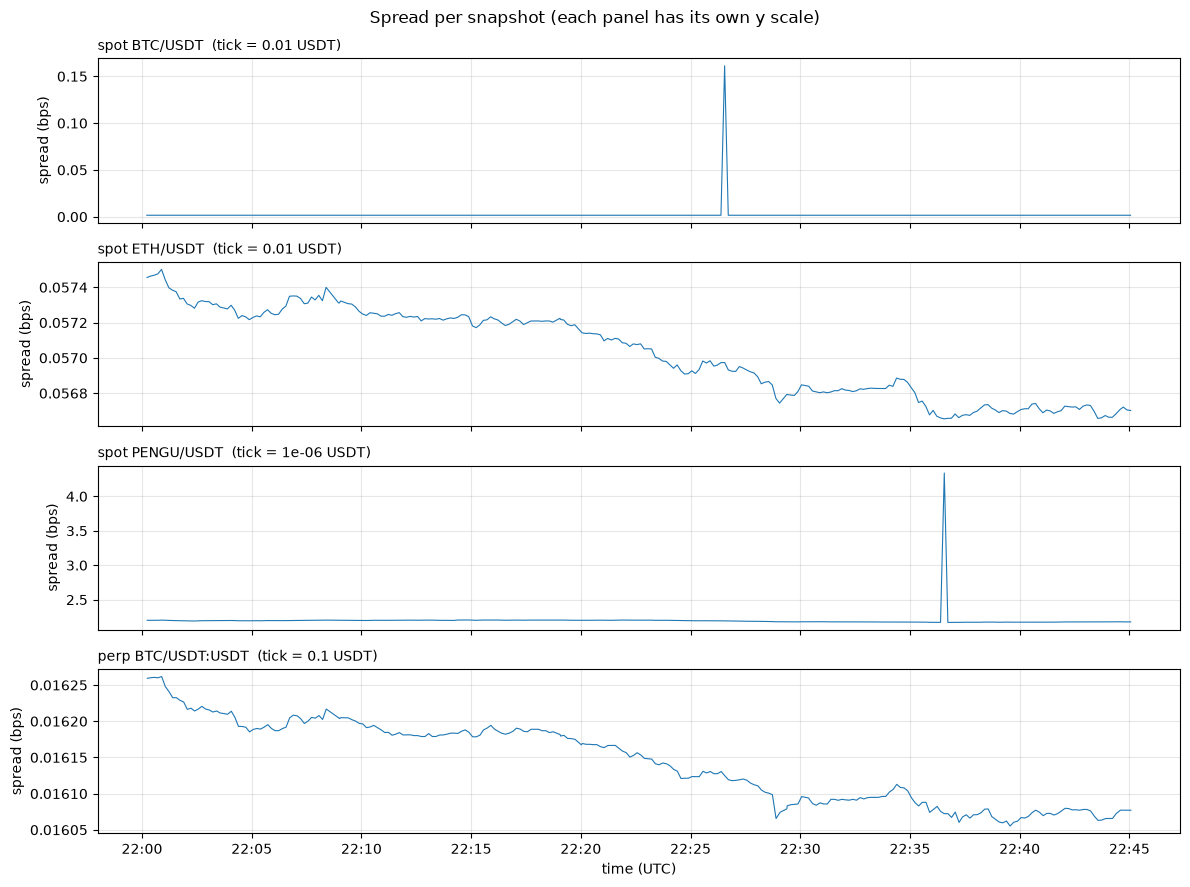

In [10]:
fig, axes = plt.subplots(len(order), 1, figsize=(12, 9), sharex=True)
for ax, market in zip(axes, order):
    m = metrics[metrics["market"] == market]
    ax.plot(m["local_request_utc"], m["spread_bps"], lw=0.8, color="tab:blue")
    ax.set_ylabel("spread (bps)")
    ax.set_title(f"{market}  (tick = {step0['ticks'][market]:g} USDT)", fontsize=10, loc="left")
    ax.grid(alpha=0.3)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz="UTC"))
axes[-1].set_xlabel("time (UTC)")
fig.suptitle("Spread per snapshot (each panel has its own y scale)")
fig.tight_layout()
plt.show()

How to read it: x is the time of the snapshot (UTC, the window of section 4); y is the spread in
bps, one point every 10 s joined by lines; one panel per market, **each with its own y scale**
(the levels differ by orders of magnitude, so compare shapes within a panel and levels with the
table of section 7). While the spread stays at one tick, the line in bps still drifts slowly:
it equals tick / mid, so it moves opposite to the price (a zoomed-in y axis makes this drift look
large). Spikes are moments when the best bid or ask was taken or pulled and the gap widened for
a few seconds.

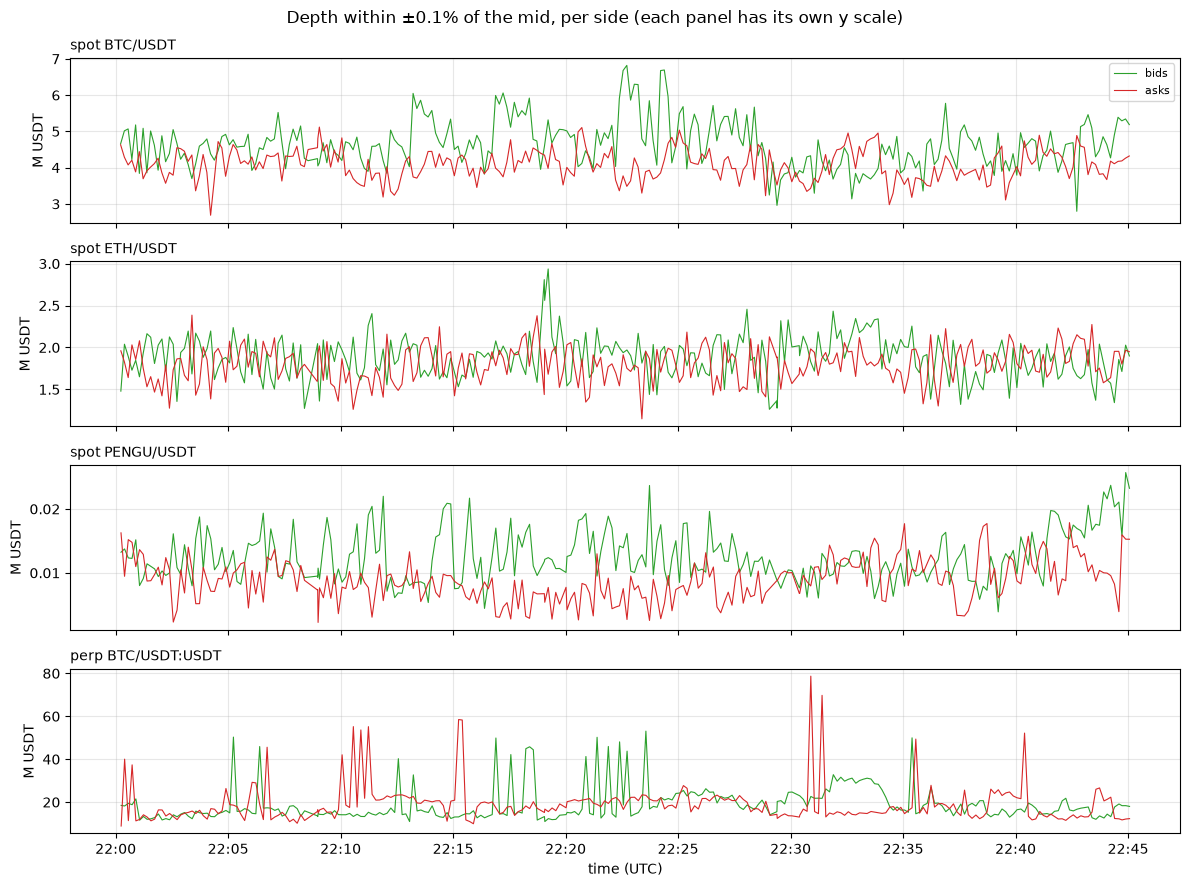

In [11]:
fig, axes = plt.subplots(len(order), 1, figsize=(12, 9), sharex=True)
for ax, market in zip(axes, order):
    m = metrics[metrics["market"] == market]
    ax.plot(m["local_request_utc"], m["depth_0.1pct_bid_usdt"] / 1e6, lw=0.8, label="bids",
            color="tab:green")
    ax.plot(m["local_request_utc"], m["depth_0.1pct_ask_usdt"] / 1e6, lw=0.8, label="asks",
            color="tab:red")
    ax.set_ylabel("M USDT")
    ax.set_title(market, fontsize=10, loc="left")
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz="UTC"))
axes[-1].set_xlabel("time (UTC)")
fig.suptitle("Depth within ±0.1% of the mid, per side (each panel has its own y scale)")
fig.tight_layout()
plt.show()

How to read it: x is time (UTC); y is the USDT resting within 0.1% of the mid, in millions;
green = bids (below the mid), red = asks (above it); one panel per market, each with its own y
scale. The gap between the two lines is the **imbalance** of the book at that moment. Jumps are
large orders placed or cancelled near the mid, or the mid itself moving so that a big resting
order enters or leaves the band.

In [12]:
metrics["depth_0.1pct_usdt"] = metrics["depth_0.1pct_bid_usdt"] + metrics["depth_0.1pct_ask_usdt"]
same_book = snaps.sort_values("local_request_utc").groupby("market")["update_id"] \
    .apply(lambda x: 100 * (x.diff() == 0).mean())
minute = (metrics.set_index("local_request_utc").groupby("market")
          [["spread_bps", "depth_0.1pct_usdt"]].resample("1min").median().reset_index())
rows = {}
for market in order:
    s = consecutive_changes(metrics[metrics["market"] == market], "spread_bps")
    d = consecutive_changes(metrics[metrics["market"] == market], "depth_0.1pct_usdt")
    sm = consecutive_changes(minute[minute["market"] == market], "spread_bps")
    su = consecutive_changes(metrics[metrics["market"] == market], "spread_usdt")
    tick = step0["ticks"][market]
    dm = consecutive_changes(minute[minute["market"] == market], "depth_0.1pct_usdt")
    rows[market] = {
        "pairs of snapshots": len(s),
        "max gap between snapshots (s)": s["gap_s"].max(),
        "same book version as previous (%)": same_book[market],
        "10 s: spread unchanged in USDT (%)": 100 * (su["change"].abs() < tick / 2).mean(),
        "10 s: median |Δ spread| (bps)": s["change"].abs().median(),
        "10 s: p90 |Δ spread| (bps)": s["change"].abs().quantile(0.9),
        "10 s: median |Δ depth ±0.1%| (%)": 100 * d["rel_change"].abs().median(),
        "10 s: p90 |Δ depth ±0.1%| (%)": 100 * d["rel_change"].abs().quantile(0.9),
        "1 min: median |Δ spread| (bps)": sm["change"].abs().median(),
        "1 min: median |Δ depth ±0.1%| (%)": 100 * dm["rel_change"].abs().median(),
        "1 min: p90 |Δ depth ±0.1%| (%)": 100 * dm["rel_change"].abs().quantile(0.9),
    }
changes = pd.DataFrame(rows)
changes.round(3)

,spot BTC/USDT,spot ETH/USDT,spot PENGU/USDT,perp BTC/USDT:USDT
pairs of snapshots,269.000,269.000,269.000,269.000
max gap between snapshots (s),25.001,34.086,34.083,34.107
same book version as previous (%),0.000,0.000,0.000,0.000
10 s: spread unchanged in USDT (%),99.257,100.000,99.257,100.000
10 s: median |Δ spread| (bps),0.000,0.000,0.000,0.000
10 s: p90 |Δ spread| (bps),0.000,0.000,0.002,0.000
10 s: median |Δ depth ±0.1%| (%),4.258,4.378,13.844,5.813
10 s: p90 |Δ depth ±0.1%| (%),13.792,13.650,29.032,57.964
1 min: median |Δ spread| (bps),0.000,0.000,0.001,0.000
1 min: median |Δ depth ±0.1%| (%),4.292,2.688,8.828,8.708


How to read it: one column per market. `pairs of snapshots`: consecutive pairs used (269 if no
snapshot failed); `max gap` shows whether any pair is further apart than 10 s. `same book
version`: share of snapshots whose `lastUpdateId` equals the previous one (the book did not
change at all in 10 s). `spread unchanged in USDT`: share of pairs with the same spread in USDT
(less than half a tick apart); it is measured in USDT because the spread in bps also moves when
only the mid moves. Rows starting with **10 s** compare each snapshot with the previous one;
rows starting with **1 min** compare the per-minute medians. `|Δ spread|` is the absolute change
in bps; `|Δ depth ±0.1%|` is the absolute **relative** change of the ±0.1% depth (both sides) in
%: 20% means the depth near the mid was 20% larger or smaller than 10 seconds (or one minute)
before. The median is the typical change; p90 is a large-but-not-rare one. Medians per minute
smooth the 10-second noise, so the 1-minute changes are usually smaller than the 10-second ones
even though more time passes.

## Limitations

- **One window.** 45 minutes on one weekday at one hour (section 4). Liquidity changes during the
  day (Asian / European / US hours), on weekends and around news; none of that is sampled here.
- **Not simultaneous.** The 4 snapshots of a round are seconds apart (section 4), so spot and
  perpetual are compared as distributions over the window, not moment by moment.
- **Snapshots, not the full stream.** Every 10 s we see the book once; orders placed and
  cancelled in between are invisible. A REST snapshot is also slightly stale by its latency.
- **Hidden liquidity.** The USDⓈ-M endpoint excludes RPI orders, and no endpoint shows iceberg
  (hidden) quantities. Visible depth is not the same as executable depth: orders can be cancelled
  before a market order reaches them.
- **Truncation.** The perpetual's 1000-level limit does not span ±1% (section 6); its ±1% depth is
  only a lower bound. Thin books may hold less than 1M USDT on a side.
- **Local clock.** Our timestamps carry the clock offset measured in step 0.
- **Retries.** `local_request_utc` is the time of the *first* attempt. In this window one spot
  BTC request failed with a network error and was retried, so that snapshot's latency (section 4,
  `max_latency_ms`) includes the wait. Afterwards the schedule caught up by running rounds back to
  back, which pushed the minute's weight to the 80% guard and triggered one short pause
  (`session_log.txt`); both show up as the `max gap between snapshots` of section 9, and the
  "10 s" changes there mix pairs from ~1 s to ~34 s apart. *Post-review:* `collect` now skips
  missed slots instead of catching up (this window was collected with the old behavior).
- **Altcoin choice.** One pair, chosen by a volume rank on one day. The hand-made list of
  tokenized equities was written *after* reading the ranking, and it decides the pick: rank 76
  (NBISB, a tokenized stock) and rank 77 (PENGU) differed by 0.02% in 24 h volume. A small,
  disclosed data-snooping risk.

## Conclusions (key takeaways)

One window: Binance, Thursday 2026-11-19, 22:00–22:45 UTC (16:00–16:45 Mexico City), 270
snapshots per market, 0 failed. Nothing here generalizes beyond that window.

1. **The spread is set by the tick, not by competition, and the BTC perpetual's spread is *wider*
   in bps: the spread half of the hypothesis is rejected here.** Both BTC books sat at exactly one
   tick in ≥ 99.6% of snapshots (spot 99.63%, perp 100%). With ticks of 0.01 and 0.1 USDT, that is
   a median of **0.0016 bps** on spot and **0.0162 bps** on the perp (10.0×, the ratio of the
   ticks). *Could the design show otherwise?* Yes: a spread wider than one tick in any snapshot
   would have been measured, and both markets could have come out either way in bps.
2. **The perpetual has far more depth near the mid: the depth half of the hypothesis holds in this
   window.** Median depth within ±0.1%, both sides: **34.7M USDT** on the perp vs **8.7M** on spot
   (4.0×); within ±0.2%: **82.5M** vs **13.6M** (6.1×). At ±1% spot has **23.6M** (complete in
   270/270), while the perp is only a lower bound, **≥ 95.6M**: its 1000-level limit never reached
   ±1% (0/270; the shortest reach was 0.199%).
3. **The altcoin's book is orders of magnitude thinner.** PENGU/USDT (rank 77 by 24 h volume, the
   first eligible pair at rank ≥ 75) had
   a median spread of **2.20 bps**, again one tick (0.000001 USDT at a price of ~0.0045), i.e.
   ~1,360× BTC spot. Median ±1% depth: **0.173M USDT** bids and **0.123M** asks vs 13.0M and 10.7M
   for BTC spot (~75× and ~87× less). Its whole bid side never held 1M USDT (0/270 snapshots,
   minimum 0.41M with only 332 levels), so a 1M USDT market sell could not be filled by the visible
   book: notebook 07 must report it as not fillable, not as a cost.
4. **Depth moves a lot while the spread does not.** The spread in USDT was unchanged between
   consecutive snapshots (10 s) in 99.26–100% of pairs in every market, but ±0.1% depth changed by a
   median of **4.3%** (BTC spot), **5.8%** (perp) and **13.8%** (PENGU) every 10 s, with a p90 of
   **58.0%** on the perp. A single snapshot can misstate the cost of a large order.

## Pending verification: free historical order-book depth from Binance

**Question:** can historical order-book depth for Binance be downloaded for free (e.g. from
data.binance.vision)?

**What was found (checked 2026-11-19), by listing the public bucket behind data.binance.vision**
(`https://s3-ap-northeast-1.amazonaws.com/data.binance.vision?delimiter=/&prefix=...`) and
downloading one file:

- **USDⓈ-M futures: yes, an aggregated version.** `data/futures/um/daily/bookDepth/<SYMBOL>/`
  has one zip per day; for BTCUSDT the first file is **2023-01-01** and the latest at the time of
  checking was **2026-11-18**. The file `BTCUSDT-bookDepth-2026-11-17.csv` has columns
  `timestamp, percentage, depth, notional`, one row every ~30 s for each percentage
  −5, −4, −3, −2, −1, −0.2, +0.2, +1, … +5 (34,560 rows for the day). The values grow with the
  percentage, which suggests **cumulative** depth from the mid up to that %, `depth` in BTC and
  `notional` in USDT, and negative = bids. **This reading is inferred, not documented:** the
  README of Binance's `binance-public-data` GitHub repository does not mention `bookDepth`, and
  the timezone of `timestamp` is not stated (probably UTC, not verified). These are not raw
  levels, so they cannot replace the snapshots of this notebook for notebook 07, but they give
  ±1% depth for the perpetual that the 1000-level REST snapshot cannot reach.
- **USDⓈ-M `bookTicker`** (best bid/ask, every update): daily files exist from 2023-05-16 to
  **2024-03-30** only; nothing later was found. Monthly `bookTicker` files also exist (not
  inspected).
- **Spot: no.** `data/spot/daily/` and `data/spot/monthly/` contain only `aggTrades`, `klines` and
  `trades`: no depth or book-ticker data were found.
- Full raw order-book history (every level, every update) was **not found** on
  data.binance.vision. Paid vendors sell it; not verified here.